# Q Actor-Critic (QAC) on Acrobot

In the REINFORCE notebook the policy was improved with the stochastic gradient-ascent step

$$\theta_{t+1} = \theta_t + \alpha\,\nabla_\theta \ln \pi(a_t \mid s_t;\theta_t)\, q_t(s_t, a_t),$$

where $q_t(s_t,a_t)$ was a **Monte Carlo** estimate: the return $G_t$. This forced us to wait until the end of every episode before updating the policy.

**Actor-critic** methods estimate $q_t(s_t,a_t)$ with **TD learning** instead. Two function approximators are learned at the same time:

* the **actor** $\pi(a \mid s;\theta)$: the policy that takes the actions;
* the **critic** $\hat q(s, a; w)$: an action-value network that evaluates (criticizes) the actor.

The simplest version is **Q actor-critic (QAC)**. At time step $t$ of each episode:

1. Generate $a_t$ following $\pi(a \mid s_t;\theta_t)$, observe $r_{t+1}, s_{t+1}$, and then generate $a_{t+1}$ following $\pi(a \mid s_{t+1};\theta_t)$.
2. **Actor** (policy update):
$$\theta_{t+1} = \theta_t + \alpha_\theta\, \nabla_\theta \ln \pi(a_t \mid s_t;\theta_t)\, \hat q(s_t, a_t; w_t).$$
3. **Critic** (value update, Sarsa with function approximation):
$$w_{t+1} = w_t + \alpha_w \Big[ r_{t+1} + \gamma\, \hat q(s_{t+1}, a_{t+1}; w_t) - \hat q(s_t, a_t; w_t) \Big] \nabla_w \hat q(s_t, a_t; w_t).$$

Remarks:

* Both networks are updated **at every time step**, not once per episode as in REINFORCE.
* No $\varepsilon$-greedy rule is needed: the policy is stochastic, so it explores by itself.
* As in REINFORCE, there is no replay buffer or target network: QAC is an **on-policy** method.

In [1]:
import copy
import gymnasium as gym
import numpy as np
import random
import time

import torch
import torch.nn as nn
from matplotlib import pyplot as plt

## Configuration

The actor and the critic have separate parameters, $\theta$ and $w$, and therefore separate learning rates, $\alpha_\theta$ and $\alpha_w$.

In [2]:
# Training configuration
NUM_EPISODES = 500
MAX_STEPS_PER_EPISODE = 500
GAMMA = 0.99
ACTOR_LEARNING_RATE = 0.0001  # alpha_theta (policy)
CRITIC_LEARNING_RATE = 0.001  # alpha_w (value function)
HIDDEN_SIZE = 128
EVAL_EVERY = 10      # check the greedy policy every EVAL_EVERY episodes
EVAL_EPISODES = 10   # number of greedy episodes used in each check

SEED = 42

## Environment

`Acrobot-v1` is a chain of two links hanging from a fixed joint. Only the joint *between* the two links has a motor. The goal is to swing the free end of the lower link above a target height.

The six observations are:

1. $\cos\theta_1$;
2. $\sin\theta_1$;
3. $\cos\theta_2$;
4. $\sin\theta_2$;
5. angular velocity $\dot\theta_1$;
6. angular velocity $\dot\theta_2$,

where $\theta_1$ is the angle of the first link measured from the downward vertical and $\theta_2$ is the angle of the second link relative to the first.

There are three actions: `0`, `1` and `2` apply a torque of $-1$, $0$ and $+1$ to the actuated joint. The agent receives reward $-1$ at every step. The episode terminates (with reward $0$) when the height of the free end,

$$h = -\cos\theta_1 - \cos(\theta_1 + \theta_2),$$

exceeds $1$, and it is truncated after 500 steps. The return is therefore approximately minus the number of steps needed to reach the goal ($-500$ if it is never reached). Gymnasium considers an average return of $-100$ to be solved.

The motor is too weak to lift the links directly: the agent has to learn to swing back and forth to pump energy into the system.

In [3]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

env = gym.make(
    "Acrobot-v1",
    max_episode_steps=MAX_STEPS_PER_EPISODE,
)
env.action_space.seed(SEED)
env.observation_space.seed(SEED)

state_size = env.observation_space.shape[0]
action_size = env.action_space.n

print("State size:", state_size)
print("Action size:", action_size)
print("Maximum episode steps:", env.spec.max_episode_steps)
print("Reward threshold:", env.spec.reward_threshold)
print("Device:", device)

State size: 6
Action size: 3
Maximum episode steps: 500
Reward threshold: -100.0
Device: cpu


## Actor: policy network

The actor is the same network used for REINFORCE. It receives the six observations and returns three **logits**, one for each torque:

$$[\cos\theta_1, \sin\theta_1, \cos\theta_2, \sin\theta_2, \dot\theta_1, \dot\theta_2]\;\longrightarrow\;[z_{-1}, z_{0}, z_{+1}].$$

A softmax converts the logits into the action probabilities $\pi(a \mid s;\theta)$. As before, the softmax is left to PyTorch's categorical distribution.

In [4]:
class PolicyNetwork(nn.Module):
    """Map an Acrobot observation to one logit per action."""

    def __init__(self, state_size, action_size, hidden_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, action_size),
        )

    def forward(self, state):
        return self.net(state)

## Critic: action-value network

The critic plays the same role as the Q-network of deep SARSA. It receives the observation and returns one action value per torque:

$$s \;\longrightarrow\; [\hat q(s, -1; w),\ \hat q(s, 0; w),\ \hat q(s, +1; w)].$$

In [5]:
class QNetwork(nn.Module):
    """Map an Acrobot observation to one action value per action."""

    def __init__(self, state_size, action_size, hidden_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, action_size),
        )

    def forward(self, state):
        return self.net(state)

In [6]:
actor_net = PolicyNetwork(state_size, action_size, HIDDEN_SIZE).to(device)
critic_net = QNetwork(state_size, action_size, HIDDEN_SIZE).to(device)

# theta and w are updated by two optimizers with their own step sizes.
actor_optimizer = torch.optim.Adam(actor_net.parameters(), lr=ACTOR_LEARNING_RATE)
critic_optimizer = torch.optim.Adam(critic_net.parameters(), lr=CRITIC_LEARNING_RATE)

## Policy helpers

During training, the agent samples from the policy; during evaluation, the greedy action is the action with the largest logit.

In QAC the next action $a_{t+1}$ is sampled **before** the update at time $t$, because the critic needs it for its Sarsa target. When $a_{t+1}$ is used at time $t+1$, the actor has already changed to $\theta_{t+1}$, so the log-probability $\ln \pi(a_{t+1} \mid s_{t+1};\theta_{t+1})$ is calculated at that moment. For this reason, sampling an action and calculating its log-probability are two separate helpers.

In [7]:
def state_to_tensor(state):
    """Convert one observation into a batch containing one state."""
    return torch.as_tensor(
        state, dtype=torch.float32, device=device
    ).unsqueeze(0)


def sample_action(state):
    """Sample an action from the current policy."""
    with torch.no_grad():
        logits = actor_net(state_to_tensor(state))

    distribution = torch.distributions.Categorical(logits=logits)
    return int(distribution.sample().item())


def log_probability(state, action):
    """Return ln pi(action | state; theta), keeping the graph for the actor update."""
    logits = actor_net(state_to_tensor(state))
    distribution = torch.distributions.Categorical(logits=logits)
    action_tensor = torch.as_tensor([action], device=device)
    return distribution.log_prob(action_tensor).squeeze()


def greedy_action(state):
    """Choose the action with the largest policy logit."""
    with torch.no_grad():
        logits = actor_net(state_to_tensor(state))

    return int(logits.argmax(dim=1).item())

### Check the network outputs

For each observation, the actor returns three logits and therefore three probabilities that sum to one. The critic returns three action values.

In [8]:
example_states = torch.zeros((4, state_size), device=device)
example_logits = actor_net(example_states)
example_probabilities = torch.softmax(example_logits, dim=1)
example_q_values = critic_net(example_states)

print("Observations:        ", tuple(example_states.shape))
print("Policy logits:       ", tuple(example_logits.shape))
print("Action probabilities:", tuple(example_probabilities.shape))
print("Probability sums:    ", example_probabilities.sum(dim=1))
print("Critic action values:", tuple(example_q_values.shape))

Observations:         (4, 6)
Policy logits:        (4, 3)
Action probabilities: (4, 3)
Probability sums:     tensor([1., 1., 1., 1.], grad_fn=<SumBackward1>)
Critic action values: (4, 3)


## Actor and critic updates

As in the previous notebooks, we let PyTorch compute the gradients. For one transition $(s_t, a_t, r_{t+1}, s_{t+1}, a_{t+1})$ we minimize two losses.

**Actor.**

$$L_{\text{actor}}(\theta) = -\,\hat q(s_t, a_t; w_t)\, \ln \pi(a_t \mid s_t;\theta).$$

The critic's value is a constant weight here (no gradient flows into $w$), so

$$-\nabla_\theta L_{\text{actor}} = \nabla_\theta \ln \pi(a_t \mid s_t;\theta)\, \hat q(s_t, a_t; w_t),$$

and one gradient-descent step on $L_{\text{actor}}$ is the actor update of Algorithm 10.1. Compared with REINFORCE, the return $G_t$ is replaced by the critic's estimate.

**Critic.**

$$L_{\text{critic}}(w) = \tfrac12 \big( y_t - \hat q(s_t, a_t; w) \big)^2,
\qquad
y_t =
\begin{cases}
r_{t+1}, & \text{if } s_{t+1} \text{ is terminal}, \\
r_{t+1} + \gamma\, \hat q(s_{t+1}, a_{t+1}; w_t), & \text{otherwise.}
\end{cases}$$

The target $y_t$ is calculated with `torch.no_grad()` (semi-gradient), so

$$-\nabla_w L_{\text{critic}} = \big( y_t - \hat q(s_t, a_t; w) \big) \nabla_w \hat q(s_t, a_t; w),$$

which is the Sarsa critic update of the book. `Adam` only adapts the step sizes $\alpha_\theta$ and $\alpha_w$.

Both updates use the critic weights $w_t$ before the critic is changed, exactly as in Algorithm 10.1. As in deep SARSA, bootstrapping stops only when the episode **terminates** (the goal is reached). When it is **truncated** after 500 steps, $s_{t+1}$ is not terminal, so $\gamma\,\hat q(s_{t+1}, a_{t+1}; w_t)$ is kept.

In [9]:
def qac_update(state, action, reward, next_state, next_action, terminated):
    """One QAC step on the transition (s, a, r, s', a')."""
    # q_hat(s_t, a_t; w): differentiated by the critic, a constant weight for the actor
    q_value = critic_net(state_to_tensor(state))[0, action]

    # Sarsa target: treated as a constant (no gradient)
    with torch.no_grad():
        next_q_value = critic_net(state_to_tensor(next_state))[0, next_action]
        target = reward + GAMMA * next_q_value * (1.0 - terminated)

    # Actor: change ln pi(a_t | s_t) in proportion to q_hat(s_t, a_t; w_t)
    actor_loss = -q_value.detach() * log_probability(state, action)
    actor_optimizer.zero_grad()
    actor_loss.backward()
    actor_optimizer.step()

    # Critic: move q_hat(s_t, a_t; w) towards the Sarsa target
    critic_loss = 0.5 * (target - q_value) ** 2
    critic_optimizer.zero_grad()
    critic_loss.backward()
    critic_optimizer.step()

    return actor_loss.item(), critic_loss.item()

### Check the Sarsa target

Before training, look at one transition. The check uses fixed actions (zero torque) and does not update the networks.

In [10]:
state, info = env.reset(seed=SEED)
action = 1  # zero torque
next_state, reward, terminated, truncated, info = env.step(action)
next_action = 1

with torch.no_grad():
    q_value = critic_net(state_to_tensor(state))[0, action].item()
    next_q_value = critic_net(state_to_tensor(next_state))[0, next_action].item()

target = reward + GAMMA * next_q_value * (1.0 - float(terminated))

print(f"reward r_(t+1)             : {reward:.1f}")
print(f"q_hat(s_t, a_t; w)         : {q_value:.4f}")
print(f"q_hat(s_(t+1), a_(t+1); w) : {next_q_value:.4f}")
print(f"Sarsa target y_t           : {target:.4f}")
print(f"TD error                   : {target - q_value:.4f}")

reward r_(t+1)             : -1.0
q_hat(s_t, a_t; w)         : 0.1863
q_hat(s_(t+1), a_(t+1); w) : 0.1891
Sarsa target y_t           : -0.8128
TD error                   : -0.9991


## Greedy evaluation helper

Online QAC is **unstable**: the actor can reach a good policy and lose it a few episodes later. In addition, the actor is trained as a *stochastic* policy, and a policy that works well when its actions are sampled does not necessarily work when it is made greedy.

For these reasons, as in deep SARSA, every `EVAL_EVERY` episodes we run the greedy policy and keep a copy of the best actor found so far. The helper below runs one episode with a given action rule (`greedy_action` or `sample_action`) and returns its total reward.

In [11]:
def run_episode(choose_action, seed):
    """Run one episode with the given action rule and return its total reward."""
    state, info = env.reset(seed=seed)
    episode_return = 0.0

    for step in range(MAX_STEPS_PER_EPISODE):
        action = choose_action(state)
        state, reward, terminated, truncated, info = env.step(action)
        episode_return += reward

        if terminated or truncated:
            break

    return episode_return

## Training

For every episode (Algorithm 10.1):

1. reset the environment and sample $a_0$ from the policy;
2. at every step: take $a_t$, observe $r_{t+1}, s_{t+1}$, sample $a_{t+1}$ from $\pi(\cdot \mid s_{t+1};\theta_t)$, update the actor and the critic with `qac_update`, and set $(s_t, a_t) \leftarrow (s_{t+1}, a_{t+1})$;
3. every `EVAL_EVERY` episodes, check the greedy policy and keep the best actor.

This is the same loop as deep SARSA, but the next action comes from the actor instead of an $\varepsilon$-greedy rule. There is one actor update and one critic update per time step, so a 500-step episode produces 500 updates of each network.

In [12]:
rewards_all_episodes = []
steps_all_episodes = []
actor_losses = []
critic_losses = []
actor_losses_all_steps = []
critic_losses_all_steps = []
eval_episodes = []
eval_returns = []

best_eval_return = -np.inf
best_weights = copy.deepcopy(actor_net.state_dict())
best_episode = 0

start_time = time.time()

for episode in range(NUM_EPISODES):
    if episode == 0:
        state, info = env.reset(seed=SEED)
    else:
        state, info = env.reset()

    action = sample_action(state)
    episode_rewards = []
    episode_actor_losses = []
    episode_critic_losses = []

    for step in range(MAX_STEPS_PER_EPISODE):
        next_state, reward, terminated, truncated, info = env.step(action)

        # The next action comes from the same policy, before it is updated.
        next_action = sample_action(next_state)
        actor_loss, critic_loss = qac_update(
            state, action, reward, next_state, next_action, float(terminated)
        )

        episode_rewards.append(reward)
        episode_actor_losses.append(actor_loss)
        episode_critic_losses.append(critic_loss)
        state = next_state
        action = next_action

        if terminated or truncated:
            break

    episode_reward = sum(episode_rewards)
    steps_taken = len(episode_rewards)
    rewards_all_episodes.append(episode_reward)
    steps_all_episodes.append(steps_taken)
    actor_losses.append(np.mean(episode_actor_losses))
    critic_losses.append(np.mean(episode_critic_losses))
    actor_losses_all_steps.extend(episode_actor_losses)
    critic_losses_all_steps.extend(episode_critic_losses)

    # Check the greedy policy and keep the best actor
    if (episode + 1) % EVAL_EVERY == 0:
        mean_eval = np.mean(
            [run_episode(greedy_action, SEED + 5000 + i) for i in range(EVAL_EPISODES)]
        )
        eval_episodes.append(episode + 1)
        eval_returns.append(mean_eval)
        if mean_eval > best_eval_return:
            best_eval_return = mean_eval
            best_weights = copy.deepcopy(actor_net.state_dict())
            best_episode = episode + 1

    if episode == 0 or (episode + 1) % 50 == 0:
        recent_mean = np.mean(rewards_all_episodes[-20:])
        print(
            f"Episode {episode + 1:4d}: "
            f"reward={episode_reward:6.0f}, "
            f"mean20={recent_mean:7.1f}, "
            f"best greedy check={best_eval_return:7.1f}"
        )

training_minutes = (time.time() - start_time) / 60
print(f"Training time: {training_minutes:.2f} minutes")
print(f"Actor updates:  {len(actor_losses_all_steps)}")
print(f"Critic updates: {len(critic_losses_all_steps)}")
print(
    "All losses finite:",
    bool(np.isfinite(actor_losses_all_steps).all() and np.isfinite(critic_losses_all_steps).all()),
)
print(f"Best greedy check: {best_eval_return:.1f} at episode {best_episode}")

Episode    1: reward=  -500, mean20= -500.0, best greedy check=   -inf
Episode   50: reward=  -207, mean20= -191.5, best greedy check= -465.9
Episode  100: reward=  -203, mean20= -227.1, best greedy check= -182.4
Episode  150: reward=  -121, mean20= -169.7, best greedy check= -182.4
Episode  200: reward=  -172, mean20= -152.6, best greedy check= -182.4
Episode  250: reward=  -413, mean20= -232.0, best greedy check= -182.4
Episode  300: reward=  -166, mean20= -161.3, best greedy check=  -95.1
Episode  350: reward=   -79, mean20= -109.0, best greedy check=  -95.1
Episode  400: reward=   -76, mean20= -102.8, best greedy check=  -95.1
Episode  450: reward=  -198, mean20= -104.5, best greedy check=  -95.1
Episode  500: reward=  -106, mean20= -103.9, best greedy check=  -95.1
Training time: 0.98 minutes
Actor updates:  80571
Critic updates: 80571
All losses finite: True
Best greedy check: -95.1 at episode 300


## Learning curves

Every step costs $-1$, so the return of an episode is approximately minus its length. The first plot shows the return of each training episode together with its rolling average. The second plot shows the critic loss, $\tfrac12(\text{TD error})^2$, averaged over each episode: it tells us how well the critic of QAC predicts its own targets.

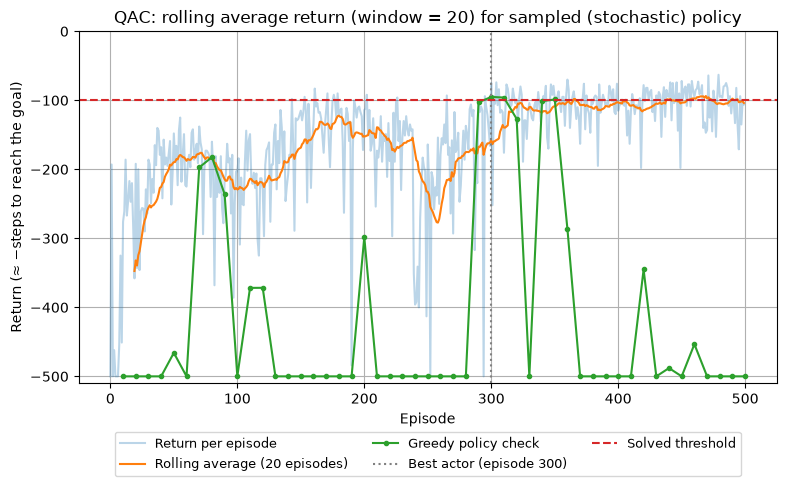

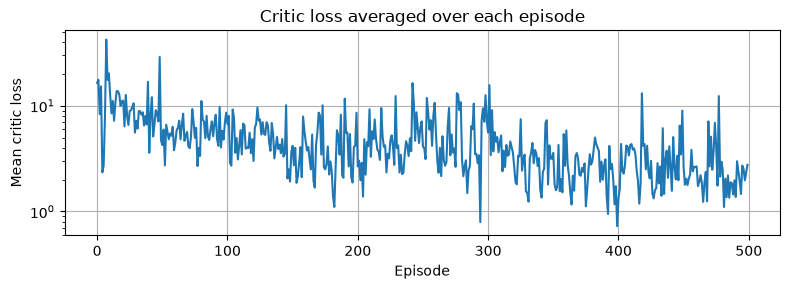

In [ ]:
window = 20
rolling_rewards = np.convolve(
    np.array(rewards_all_episodes),
    np.ones(window) / window,
    mode="valid",
)

plt.figure(figsize=(8, 5))
plt.plot(rewards_all_episodes, alpha=0.3, label="Return per episode")
plt.plot(np.arange(window - 1, NUM_EPISODES), rolling_rewards, label=f"Rolling average ({window} episodes)")
plt.plot(eval_episodes, eval_returns, "o-", ms=3, label="Greedy policy check")
plt.axvline(best_episode, color="grey", linestyle=":", label=f"Best actor (episode {best_episode})")
plt.axhline(-100, color="tab:red", linestyle="--", label="Solved threshold")
plt.xlabel("Episode")
plt.ylabel("Return (≈ -steps to reach the goal)")
plt.ylim(-MAX_STEPS_PER_EPISODE - 10, 0)
plt.title(f"QAC: rolling average return (window = {window}) for sampled (stochastic) policy")
plt.grid(True)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3))
plt.plot(critic_losses)
plt.yscale("log")
plt.xlabel("Episode")
plt.ylabel("Mean critic loss")
plt.title("Critic loss averaged over each episode")
plt.grid(True)
plt.tight_layout()
plt.show()

## Evaluate the policy

Training samples actions from the policy, so its returns do not directly measure the greedy policy. We evaluate over 100 fresh episodes:

1. the actor at the **end** of training, choosing the greedy action;
2. the same actor **sampling** its actions, as during training;
3. the **best** actor kept during training, choosing the greedy action.

The best actor is then kept in `actor_net` for the rollout and for saving.

In [14]:
actor_net.eval()
last_greedy_returns = np.array(
    [run_episode(greedy_action, SEED + 1000 + i) for i in range(100)]
)
last_sampled_returns = np.array(
    [run_episode(sample_action, SEED + 1000 + i) for i in range(100)]
)

actor_net.load_state_dict(best_weights)
best_greedy_returns = np.array(
    [run_episode(greedy_action, SEED + 1000 + i) for i in range(100)]
)

for name, returns in [
    ("last actor, greedy ", last_greedy_returns),
    ("last actor, sampled", last_sampled_returns),
    ("best actor, greedy ", best_greedy_returns),
]:
    print(
        f"{name}: mean {returns.mean():7.1f} | std {returns.std():6.1f} | "
        f"min {returns.min():5.0f} | max {returns.max():5.0f} | "
        f"solved (mean >= -100): {returns.mean() >= -100}"
    )

last actor, greedy : mean  -500.0 | std    0.0 | min  -500 | max  -500 | solved (mean >= -100): False
last actor, sampled: mean  -114.4 | std   59.7 | min  -500 | max   -73 | solved (mean >= -100): False
best actor, greedy : mean   -90.0 | std   20.9 | min  -212 | max   -64 | solved (mean >= -100): True


## One greedy rollout

Instead of opening a separate rendering window, record one greedy episode and plot the height of the free end together with the applied torque. Since $\cos(\theta_1+\theta_2) = \cos\theta_1\cos\theta_2 - \sin\theta_1\sin\theta_2$, the height

$$h = -\cos\theta_1 - \cos(\theta_1 + \theta_2)$$

can be calculated directly from the observation. A successful policy alternates the torque to swing the links higher and higher until $h$ crosses the target line.

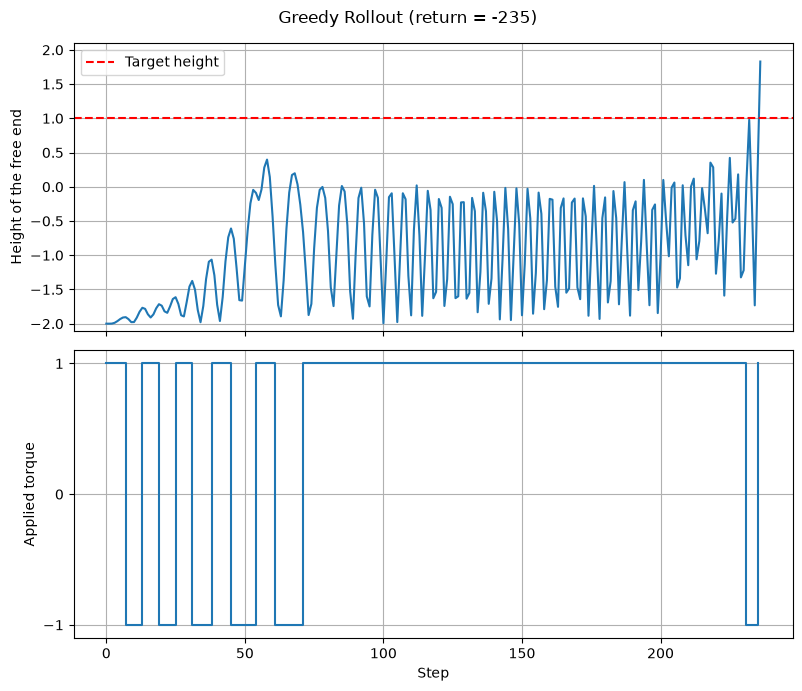

Rollout return: -235
Rollout steps:  236


In [15]:
state, info = env.reset(seed=SEED + 2000)
rollout_states = [state.copy()]
rollout_torques = []
rollout_return = 0.0

for step in range(MAX_STEPS_PER_EPISODE):
    action = greedy_action(state)
    state, reward, terminated, truncated, info = env.step(action)
    rollout_states.append(state.copy())
    rollout_torques.append(action - 1)  # actions 0, 1, 2 -> torque -1, 0, +1
    rollout_return += reward

    if terminated or truncated:
        break

rollout_states = np.array(rollout_states)
cos_1, sin_1 = rollout_states[:, 0], rollout_states[:, 1]
cos_2, sin_2 = rollout_states[:, 2], rollout_states[:, 3]
tip_height = -cos_1 - (cos_1 * cos_2 - sin_1 * sin_2)
time_steps = np.arange(len(rollout_states))

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
axes[0].plot(time_steps, tip_height)
axes[0].axhline(1.0, color="red", linestyle="--", label="Target height")
axes[0].set_ylabel("Height of the free end")
axes[0].set_ylim(-2.1, 2.1)
axes[0].grid(True)
axes[0].legend()

axes[1].step(time_steps[:-1], rollout_torques, where="post")
axes[1].set_yticks([-1, 0, 1])
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Applied torque")
axes[1].grid(True)

fig.suptitle(f"Greedy Rollout (return = {rollout_return:.0f})")
fig.tight_layout()
plt.show()

print(f"Rollout return: {rollout_return:.0f}")
print(f"Rollout steps:  {len(rollout_states) - 1}")

## Save the trained network

The learned policy is the actor, so we store the state dictionary of the best actor; the critic is only needed during training. The same `PolicyNetwork` architecture must be created before these weights are loaded later. We also check that the reloaded network chooses the same greedy action, and save the training returns so that they can be compared with A2C in the next notebook.

To watch the saved actor, run from this folder:

```
python run_qac_acrobot_policy.py --episodes 3
```

In [16]:
MODEL_PATH = "qac_acrobot_policy.pth"
torch.save(actor_net.state_dict(), MODEL_PATH)

RETURNS_PATH = "qac_acrobot_returns.npy"
np.save(RETURNS_PATH, np.array(rewards_all_episodes))

# Check that the saved state dictionary can be loaded.
saved_weights = torch.load(MODEL_PATH, map_location=device, weights_only=True)
check_net = PolicyNetwork(state_size, action_size, HIDDEN_SIZE).to(device)
check_net.load_state_dict(saved_weights)
check_net.eval()

check_state, info = env.reset(seed=SEED + 3000)
check_state_tensor = state_to_tensor(check_state)

with torch.no_grad():
    original_action = actor_net(check_state_tensor).argmax(dim=1).item()
    reloaded_action = check_net(check_state_tensor).argmax(dim=1).item()

print("Saved and reloaded:", MODEL_PATH)
print("Saved training returns:", RETURNS_PATH)
print("Greedy actions match:", original_action == reloaded_action)
env.close()

Saved and reloaded: qac_acrobot_policy.pth
Saved training returns: qac_acrobot_returns.npy
Greedy actions match: True


## Why is QAC noisy?

In Acrobot every reward is $-1$, so every action value $\hat q(s, a; w)$ is negative (between about $-1/(1-\gamma) = -100$ and $0$). The actor loss $-\hat q(s_t,a_t;w_t)\ln\pi(a_t \mid s_t;\theta)$ therefore **decreases** the probability of *every* sampled action; good actions are only decreased a little less than bad ones. On average the update still points in the right direction, but every single update is large and noisy.

The consequences are visible above: the return of the sampled policy improves slowly, the greedy checks jump between success and failure, and the greedy actor can get stuck applying the same torque for many steps (look at the torque in the rollout), so the links spin instead of swinging higher. Keeping the best actor hides part of this instability, but does not remove it.